In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.insert(0, "../../")

from RealTrace_paper_analysis.plotting_src.read_ggp_run import * # you might need to change these two line, such that you can use read ggp_run
from RealTrace_paper_analysis.simulations.cells_simulation import * # you might need to change these two line, such that you can use read ggp_run

from RealTrace_paper_analysis.plotting_src.cells_utils import *
from RealTrace_paper_analysis.plotting_src.read_utils import *
from RealTrace_paper_analysis.plotting_src.header_settings import *
from RealTrace_paper_analysis.plotting_src.naive_rates import *



%config InlineBackend.figure_format ='retina'


header_setting.py: using old naming


In [3]:
def sort_by_mean_time(cells):
    times = [ np.median(cell.time) for cell in cells ]
    return np.array(cells)[np.argsort(times)]


### C elegans

In [4]:
filename_worm = "../../data_realtrace_paper/celegans_data/formatted_f01234578_b_prediction.csv"
worm_data = df2ggp_cells(pd.read_csv(filename_worm, skiprows=header_lines(filename_worm)))

In [5]:
def get_from_all_cells(cells, q, time_window=[None, None]):    
    time = np.concatenate([cell.time/60. for cell in cells])
    
    if q == "l":
        yaxis = np.concatenate([cell.mean_l for cell in cells])*60. # in h
    elif q == "naive_l":
        yaxis = np.concatenate([cell.naive_l for cell in cells])*60. # in h
    elif q == "q":
        yaxis = np.concatenate([cell.mean_q for cell in cells])*60. # in h
    elif q == "c":
        yaxis = np.concatenate([cell.mean_g/np.exp(cell.mean_x) for cell in cells])
    elif q == "x":
        yaxis = np.concatenate([cell.mean_x for cell in cells])
    elif q == "log_length":
        yaxis = np.concatenate([cell.log_length for cell in cells])
    elif q == "s":
        yaxis = np.concatenate([np.exp(cell.mean_x) for cell in cells])
    elif q == "n":
        yaxis = np.concatenate([cell.time for cell in cells])
        
    if time_window!=[None, None]:
        yaxis = yaxis[(time>=time_window[0])*(time<=time_window[1])]
        time  =  time[(time>=time_window[0])*(time<=time_window[1])]
        
    return time, yaxis
        
from scipy import stats
import matplotlib


def moult_time(cell,t_win=[None, None], return_frame=False):
    frame_window = (cell.time/60>t_win[0]) * (cell.time/60<t_win[1]) * (cell.mean_l<0)
    
    frame = np.argmin(cell.mean_x[frame_window])
    t = cell.time[frame_window][frame]/60.
    if return_frame:
        return t, np.argwhere(cell.time==cell.time[frame_window][frame])[0][0]
    return t

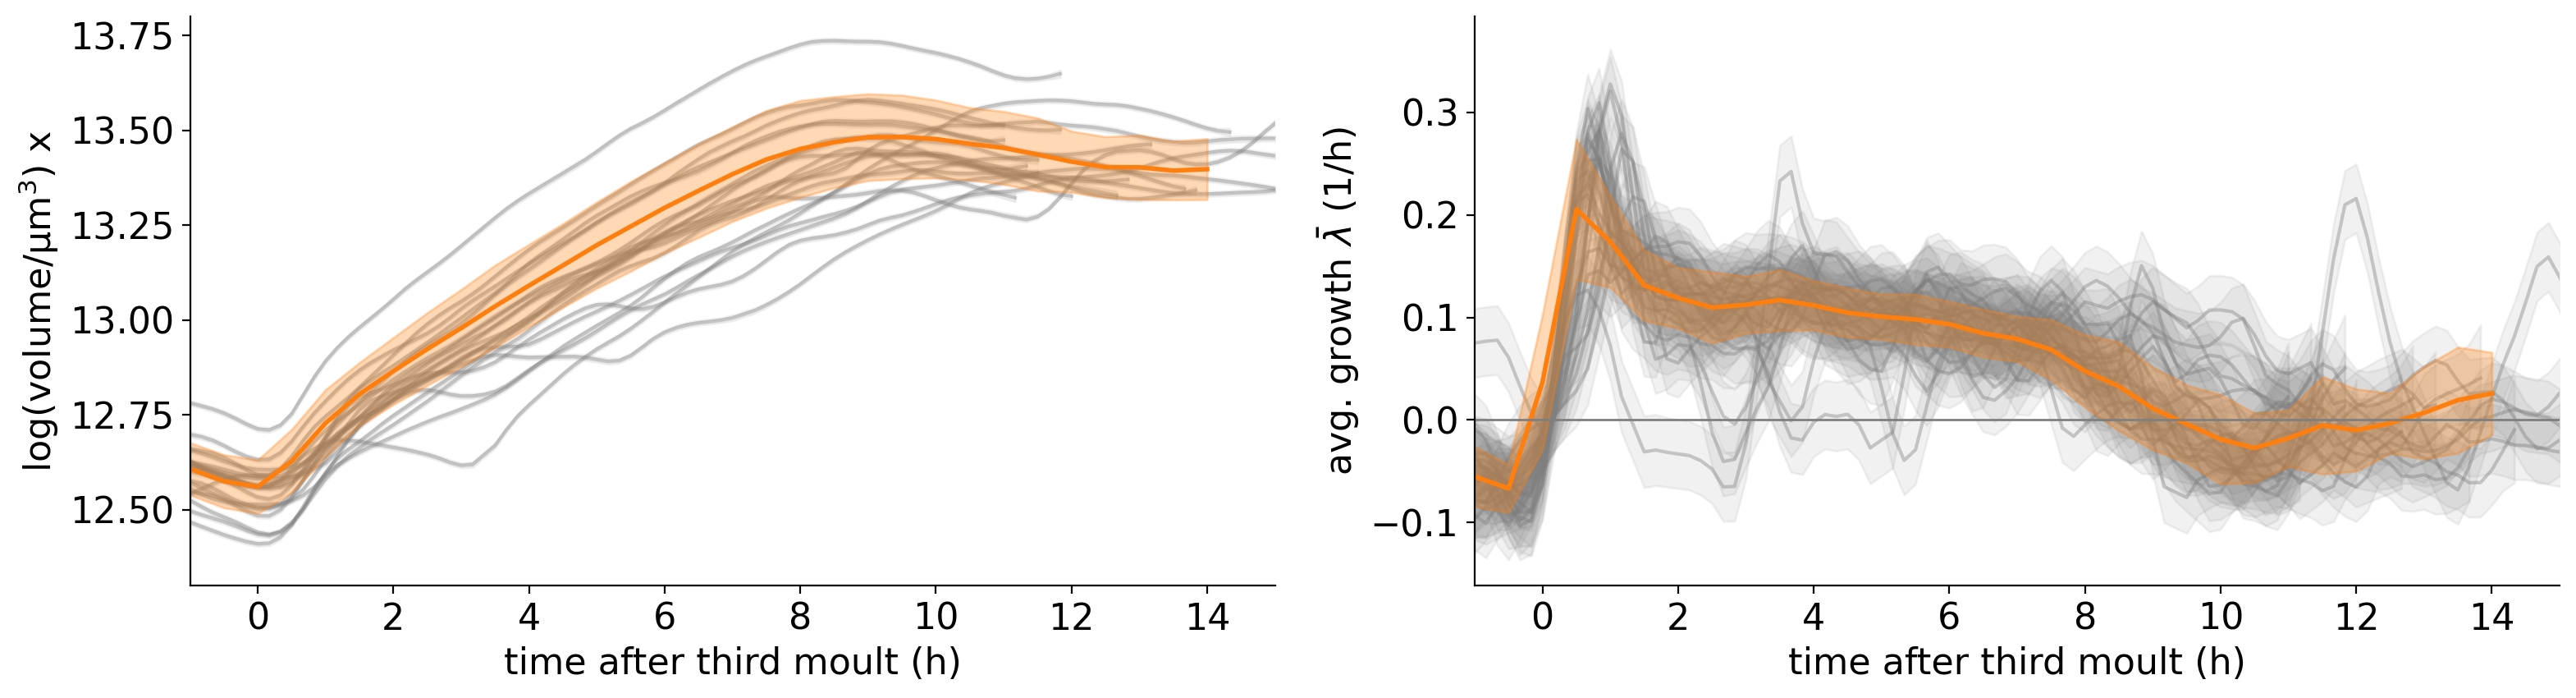

In [6]:



def plot_mean_rate_in_time(cells, 
                           title=None, 
                           rate ='l', 
                           xlim = [None, None],
                           plot_file=None,
                           color="tab:blue",
                           normalize=None, 
                           ylabel=None):
    
    fig, ax = plt.subplots(1,2, figsize=(16,4.5))
    ax = ax.ravel()
    
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()

    
    time = []
    
    idx = np.random.choice(len(cells), 20, replace=False)

    for i, cell in enumerate(cells):
        t1 = moult_time(cell, [5, 12])
        cell_time = cell.time/60.-t1
        time.append(cell_time)
        
        if i in idx:
            ax[0].plot(cell_time, cell.mean_x, color="tab:grey", alpha=0.4, zorder=-1)
            ax[0].fill_between(cell_time, 
                               (cell.mean_x-np.sqrt(cell.cov_xx)), 
                               (cell.mean_x+np.sqrt(cell.cov_xx)), 
                               color="tab:grey", alpha=0.1, zorder=-1)  
            
            ax[1].plot(cell_time, cell.mean_l*60, color="tab:grey", alpha=0.4, zorder=-1)  
            ax[1].fill_between(cell_time, 
                               (cell.mean_l-np.sqrt(cell.cov_ll))*60, 
                               (cell.mean_l+np.sqrt(cell.cov_ll))*60, 
                               color="tab:grey", alpha=0.1, zorder=-1)  
        
    time = np.concatenate(time)
        
    for i, rate in enumerate(["x", "l"]):
        _, yaxis = get_from_all_cells(cells, rate)

        bins_time = np.arange(xlim[0], xlim[1], 0.5)
        bin_value, bin_edges, binnumber = stats.binned_statistic(time,yaxis, statistic='mean', bins=bins_time)
        bin_std, _, _= stats.binned_statistic(time,yaxis, statistic='std', bins=bins_time)

        ax[i].plot(bin_edges[:-1], 
                    bin_value, 
                    color=color, 
                    alpha=1, lw=2)
        ax[i].fill_between(bin_edges[:-1], 
                        bin_value-bin_std, bin_value+bin_std, 
                        color=color, 
                        alpha=0.3,
                        zorder=1)
    
        
    ax[1].axhline(0,color="tab:grey", lw=1)
    ax[0].set_ylim(12.3, 13.8)

    for a in ax:
        a.set_xlim(xlim)
        a.set_xlabel("time after third moult (h)")

    ax[0].set_ylabel("log(volume/$\mathrm{\mu m^3}$) x") 
    ax[1].set_ylabel(r"avg. growth $\bar{\lambda}$ (1/h)")

    fig.tight_layout()
    if plot_file != None: 
        fig.savefig(plot_file, dpi=600, bbox_inches='tight')
    plt.show()
    return fig, ax

 
fig, ax = plot_mean_rate_in_time(worm_data, rate='l',
                                 xlim=[-1, 15], 
                                 color= "tab:orange",
                                 plot_file=None )

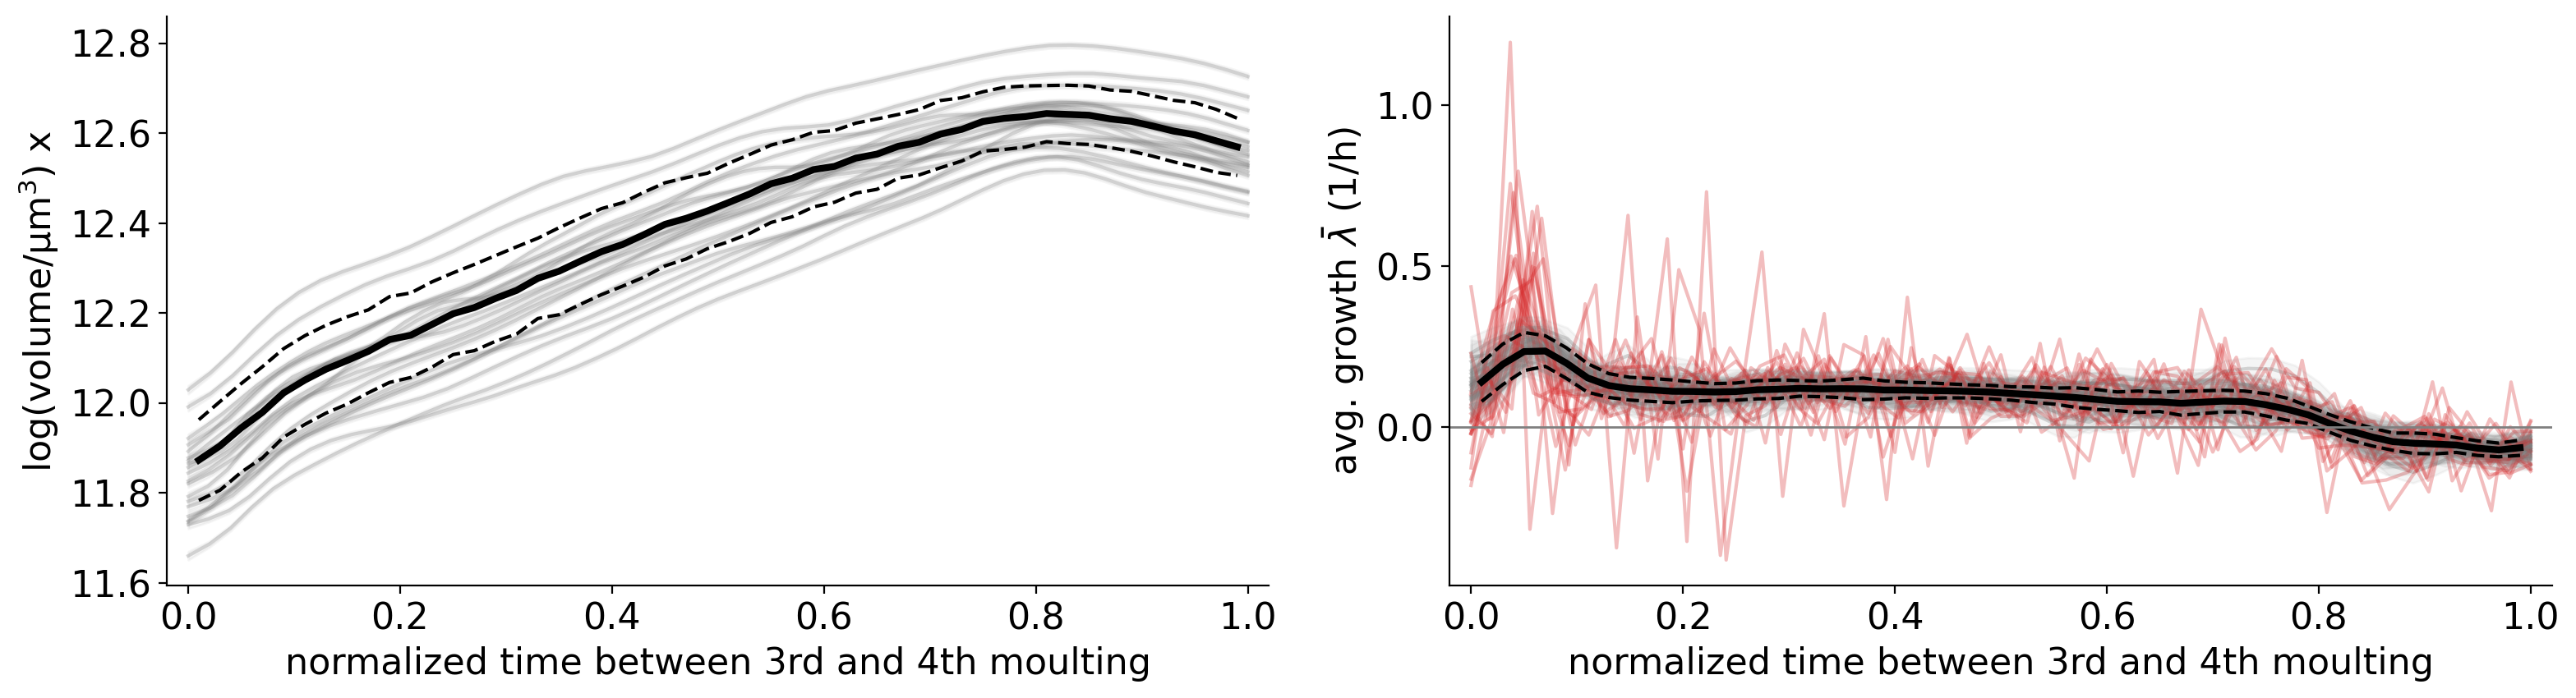

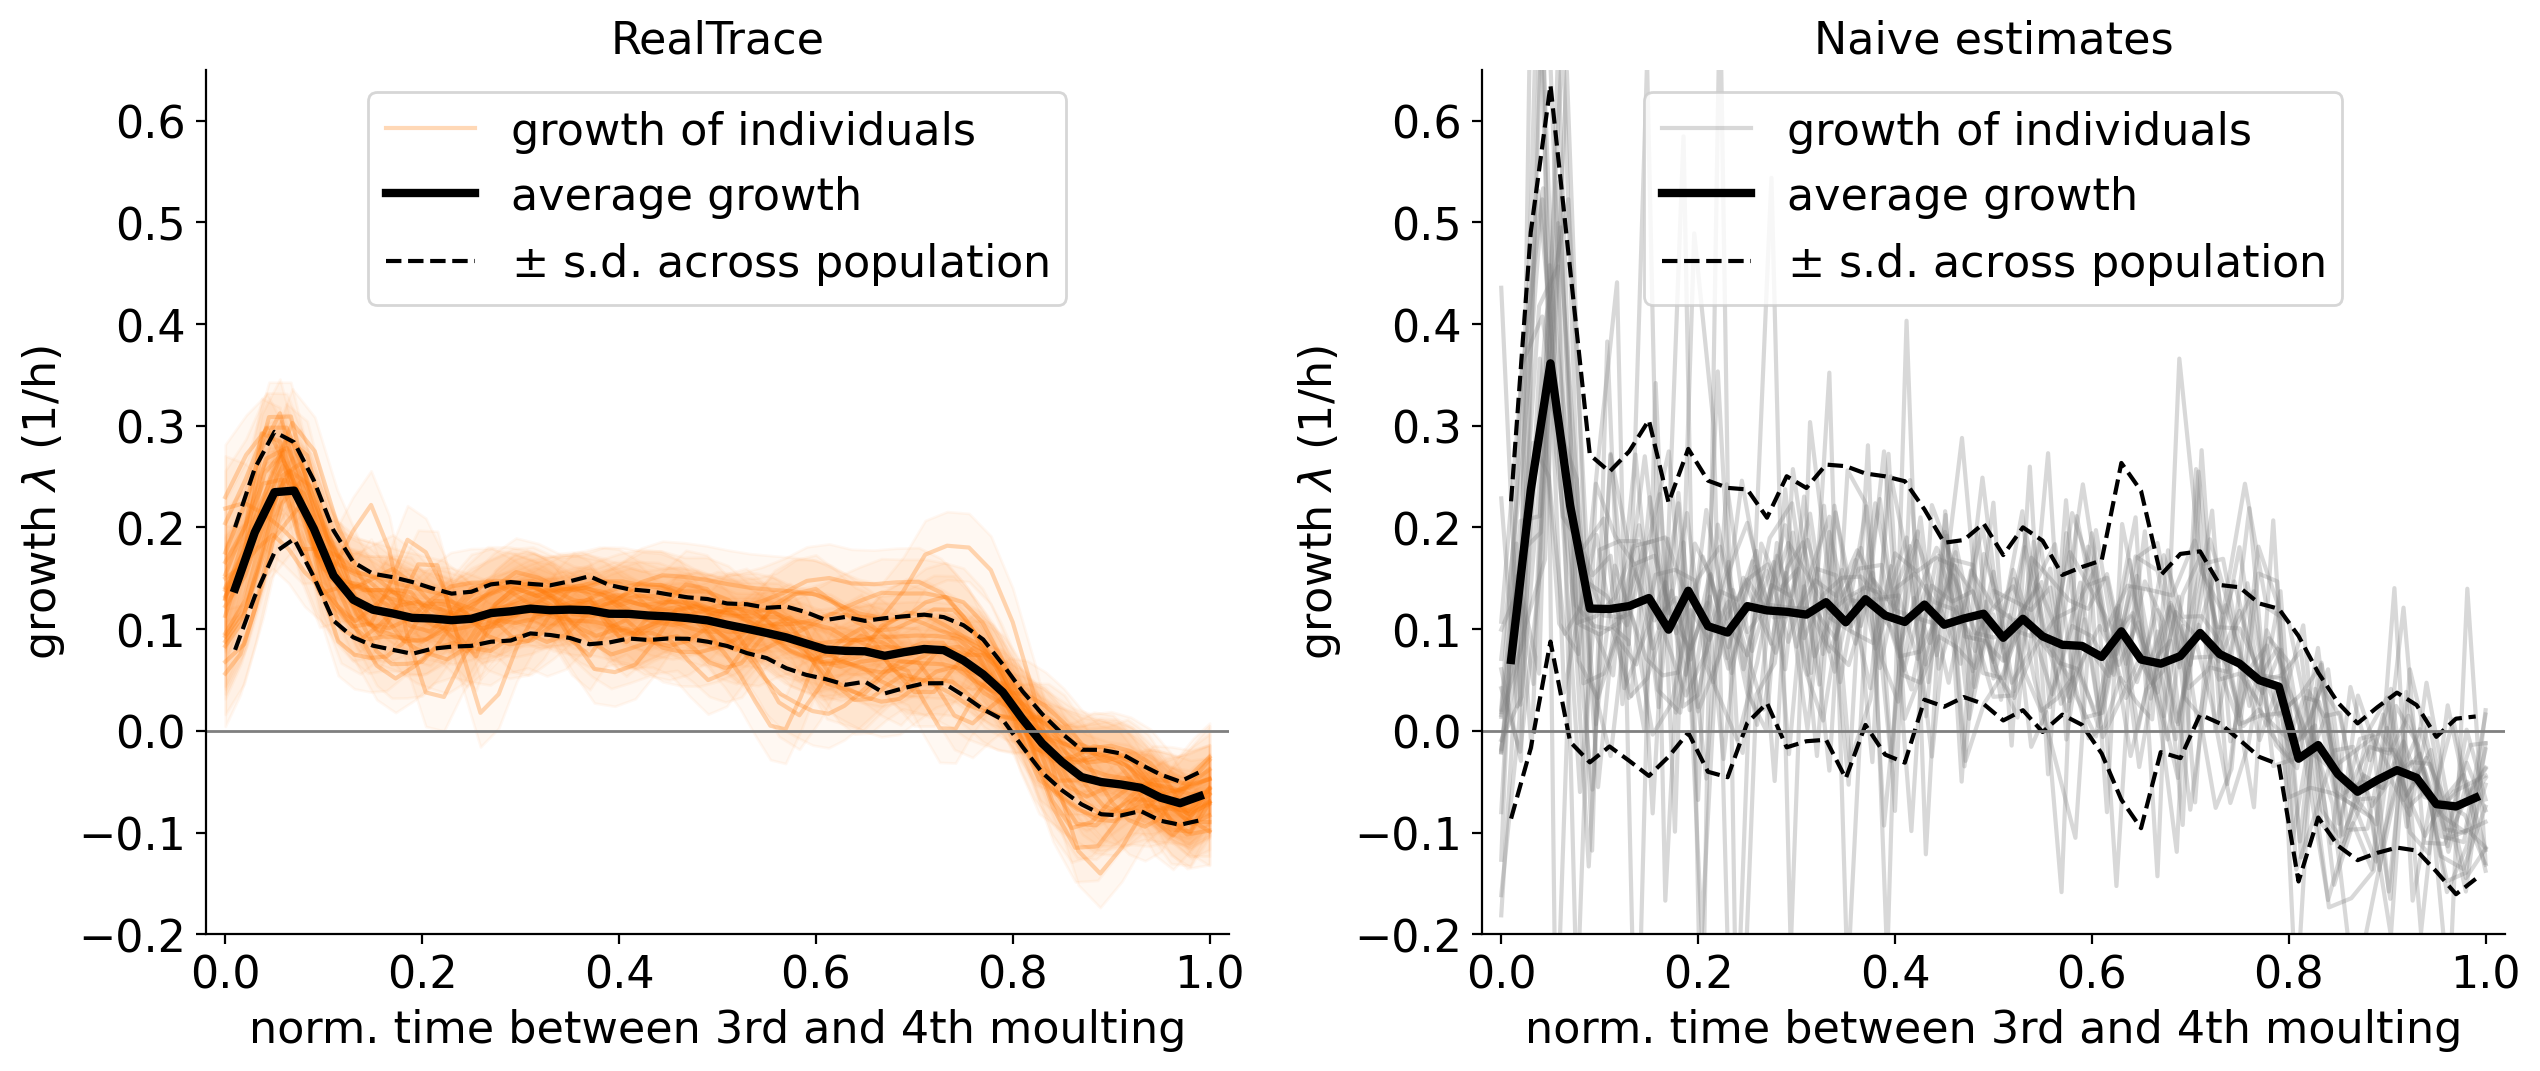

In [9]:
np.random.seed(1)

def plot_comparison_naive_realtrace(cells_orig, 
                           title=None, 
                           rate ='l', 
                           xlim = [None, None],
                           plot_file=None,
                           color="tab:blue",
                           normalize=None, 
                           ylabel=None):
    
    fig, ax = plt.subplots(1,2, figsize=(FULL_SIZE,FULL_HEIGHT*1.4))
    ax = ax.ravel()
    
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()

    cells = copy.deepcopy(cells_orig)
    time = []
    idx = np.random.choice(len(cells), 20, replace=False)
    
    label = "growth of individuals"

    for i, cell in enumerate(cells):
        t1, frame = moult_time(cell, [5, 12], True)
        cells[i].naive_l = np.diff(cell.log_length)/np.diff(cell.time)
        cells[i].naive_l = cell.naive_l[:frame]
        
        cells[i].time = cell.time[:frame]
        
        cells[i].mean_l = cell.mean_l[:frame]
        cells[i].cov_ll = cell.cov_ll[:frame]
        
        cell_time = cells[i].time/cells[i].time[-1]
        
        time.append(cell_time)
        
        if i in idx:
            ax[0].plot(cell_time, cells[i].mean_l*60, color="tab:orange", alpha=0.3, zorder=-1,
                      label=label) 
            
            cmap =  matplotlib.pyplot.get_cmap("Blues")

            ax[1].plot(cell_time, cells[i].naive_l*60, color="tab:grey", alpha=0.3, zorder=-1,
                      label=label)


            label=None
                        
            ax[0].fill_between(cell_time, 
                               (cells[i].mean_l-np.sqrt(cells[i].cov_ll))*60, 
                               (cells[i].mean_l+np.sqrt(cells[i].cov_ll))*60, 
                               color="tab:orange", alpha=0.05, zorder=-1)  
        
    time = np.concatenate(time)
        
    for i, rate in enumerate([ "l", "naive_l"]):
        _, yaxis = get_from_all_cells(cells, rate)

        dt_bin = 0.02
        bins_time = np.arange(0, 1+dt_bin, dt_bin)
        bin_value, bin_edges, binnumber = stats.binned_statistic(time,yaxis, statistic='mean', bins=bins_time)
        bin_std, _, _= stats.binned_statistic(time,yaxis, statistic='std', bins=bins_time)

        ax[i].plot(bin_edges[:-1] + np.diff(bin_edges)/2., 
                    bin_value, 
                    color=color, 
                    alpha=1, 
                    lw=3,
                    label="average growth")
        ax[i].plot(bin_edges[:-1] + np.diff(bin_edges)/2., 
                        bin_value-bin_std ,
                        color=color, 
                        alpha=1,
                        ls="--",
                        zorder=1, 
                          label= "$\pm$ s.d. across population")
        ax[i].plot(bin_edges[:-1] + np.diff(bin_edges)/2., 
                        bin_value+bin_std, 
                        color=color, 
                        alpha=1, ls="--",
                        zorder=1)
    
        
    ax[0].axhline(0,color="tab:grey", lw=1)
    ax[1].axhline(0,color="tab:grey", lw=1)

    ax[0].legend(bbox_to_anchor=(0.5, 1), loc="upper center")
    ax[1].legend(bbox_to_anchor=(0.5, 1), loc="upper center")
    
    ax[0].set_ylim(-0.2, 0.65)
    ax[1].set_ylim(-0.2, 0.65)

    for a in ax:
        a.set_xlim(xlim)
        a.set_xlabel("norm. time between 3rd and 4th moulting")

    ax[0].set_title(r"RealTrace", y=1.)
    ax[1].set_title(r"Naive estimates", y=1.)
    
    ax[0].set_ylabel(r"growth $\lambda$ (1/h)")
    ax[1].set_ylabel(r"growth $\lambda$ (1/h)")

    fig.tight_layout()
    if plot_file != None: 
        fig.savefig(plot_file, dpi=600, bbox_inches='tight')
    plt.show()
    return fig, ax

 
fig, ax = plot_comparison_naive_realtrace(worm_data, rate='l',
                                          xlim=[-0.02, 1.02], 
                                          color= "black",
                                          plot_file="../../figures_for_method_paper/supp/celegans/celegans_growth.pdf")




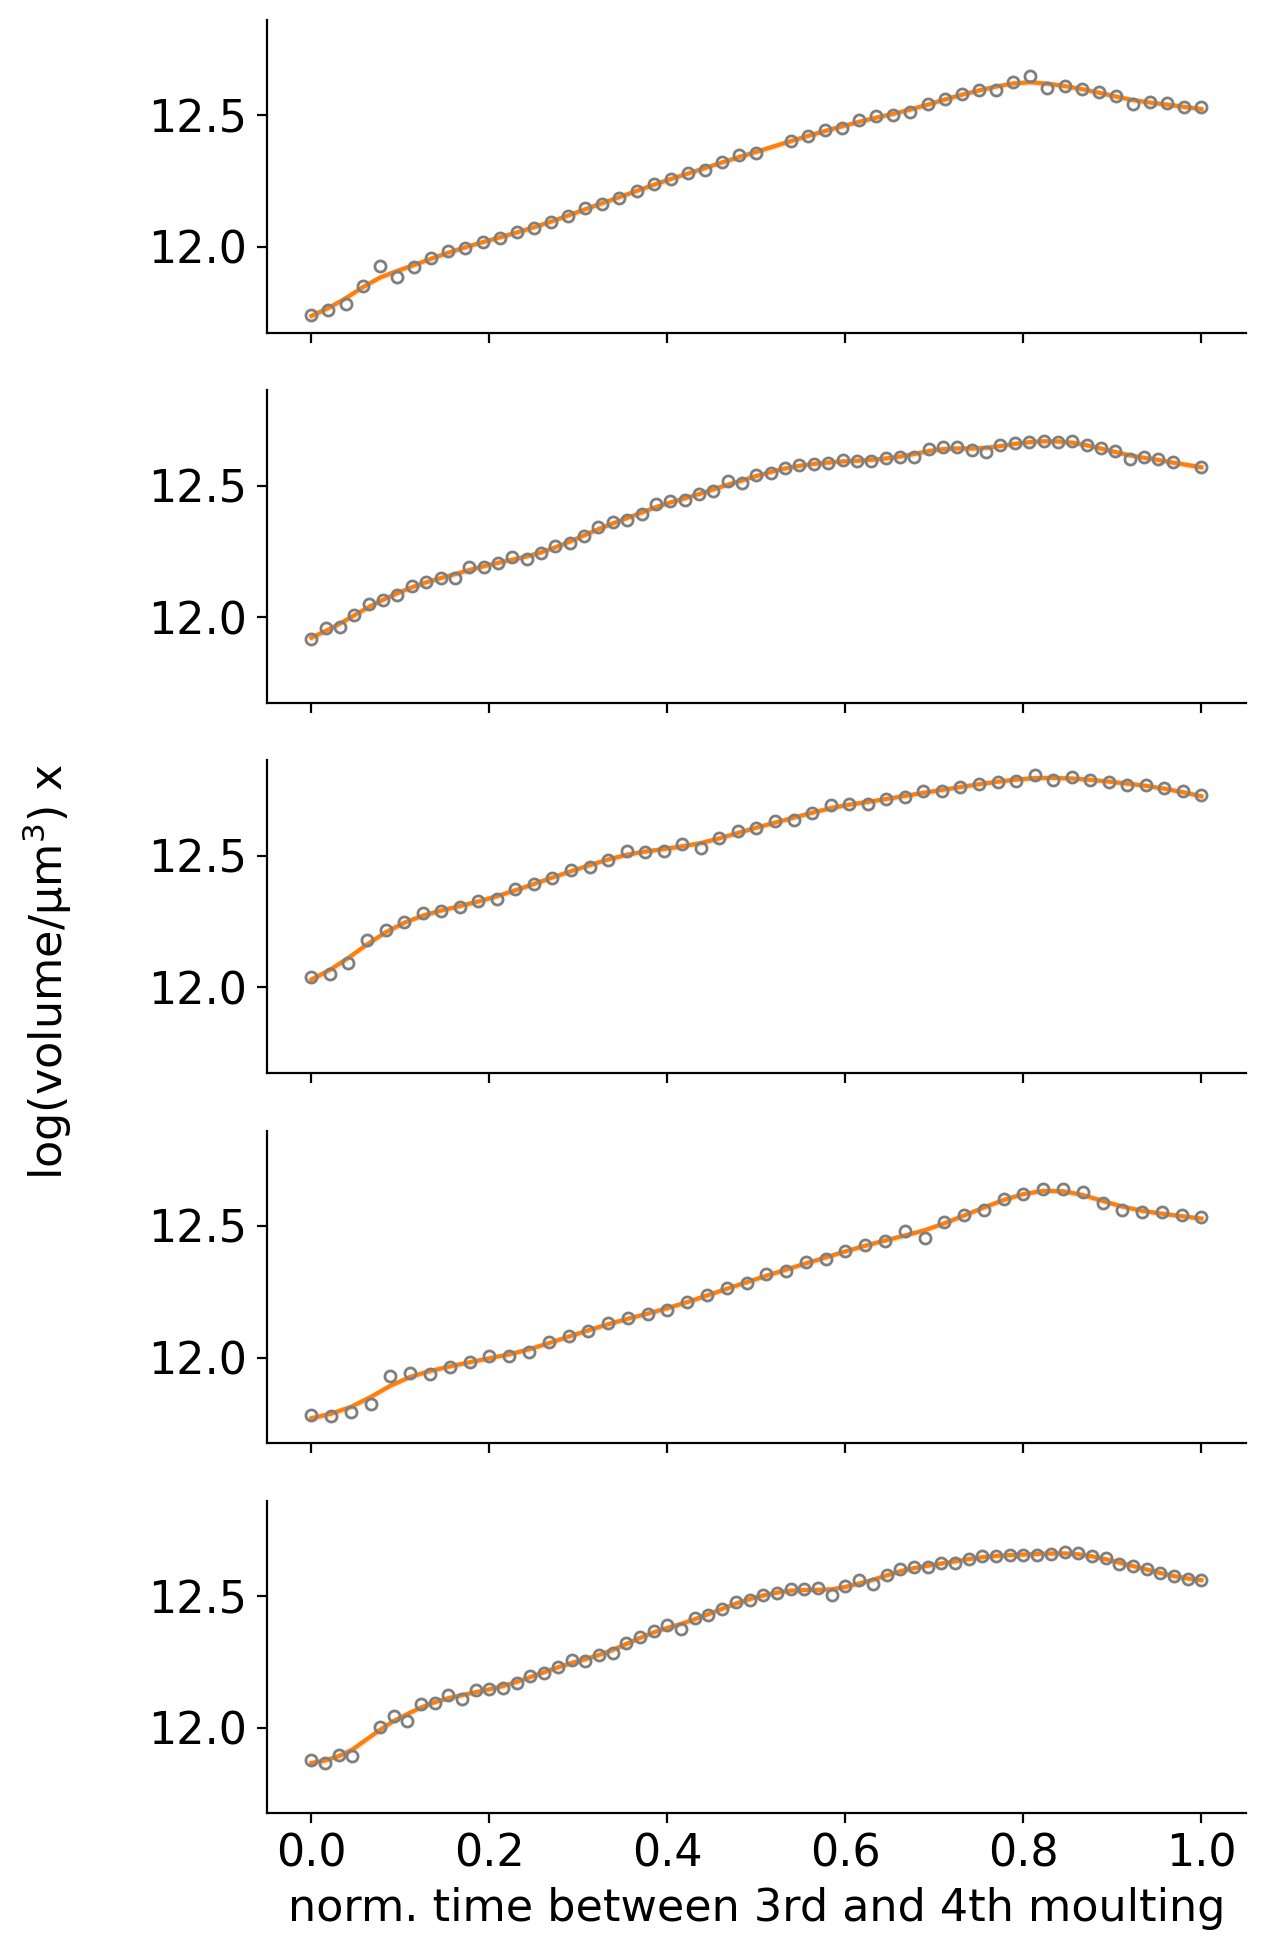

array([<AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>,
       <AxesSubplot:>], dtype=object)

In [34]:
def sc_size(all_cells, n_cells, outfile=None):
                         
    fig, axes = plt.subplots(n_cells,1, figsize=(FULL_SIZE/2,FULL_HEIGHT*n_cells*0.5), sharey=True, sharex=True)
    ax = axes.ravel()
    cells = copy.deepcopy(all_cells)
        
    np.random.seed(1)
    cells_idx = np.random.choice(np.arange(len(cells)), n_cells, replace=False)

        
    for i, idx in enumerate(cells_idx):
        t1, frame = moult_time(cells[idx], [5, 12], True)
            
        time = (cells[idx].time - cells[idx].time[0])[:frame]
        time = time/time[-1]


        ax[i].plot(time, cells[idx].mean_x[:frame], color="tab:orange", label="RealTrace")
        ax[i].fill_between(time, 
                             (cells[idx].mean_x-np.sqrt(cells[idx].cov_xx))[:frame],
                             (cells[idx].mean_x+np.sqrt(cells[idx].cov_xx))[:frame], 
                                color="tab:orange", alpha=0.2)
        ax[i].plot(time, cells[idx].log_length[:frame],'o', markersize=4, mfc='none', color="tab:grey", alpha=1, label="raw")


    ax[-1].set_xlabel("norm. time between 3rd and 4th moulting")

    fig.supylabel("log(volume/$\mathrm{\mu m^3}$) x") 

    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()   
        # a.set_ylim(-0.15, 0.55)

    fig.tight_layout()
    
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    plt.show()
    fig.clear()
    plt.close(fig)
    return ax


sc_size(worm_data, 5,  outfile="../../figures_for_method_paper/supp/celegans/sw_celegans_size.pdf")




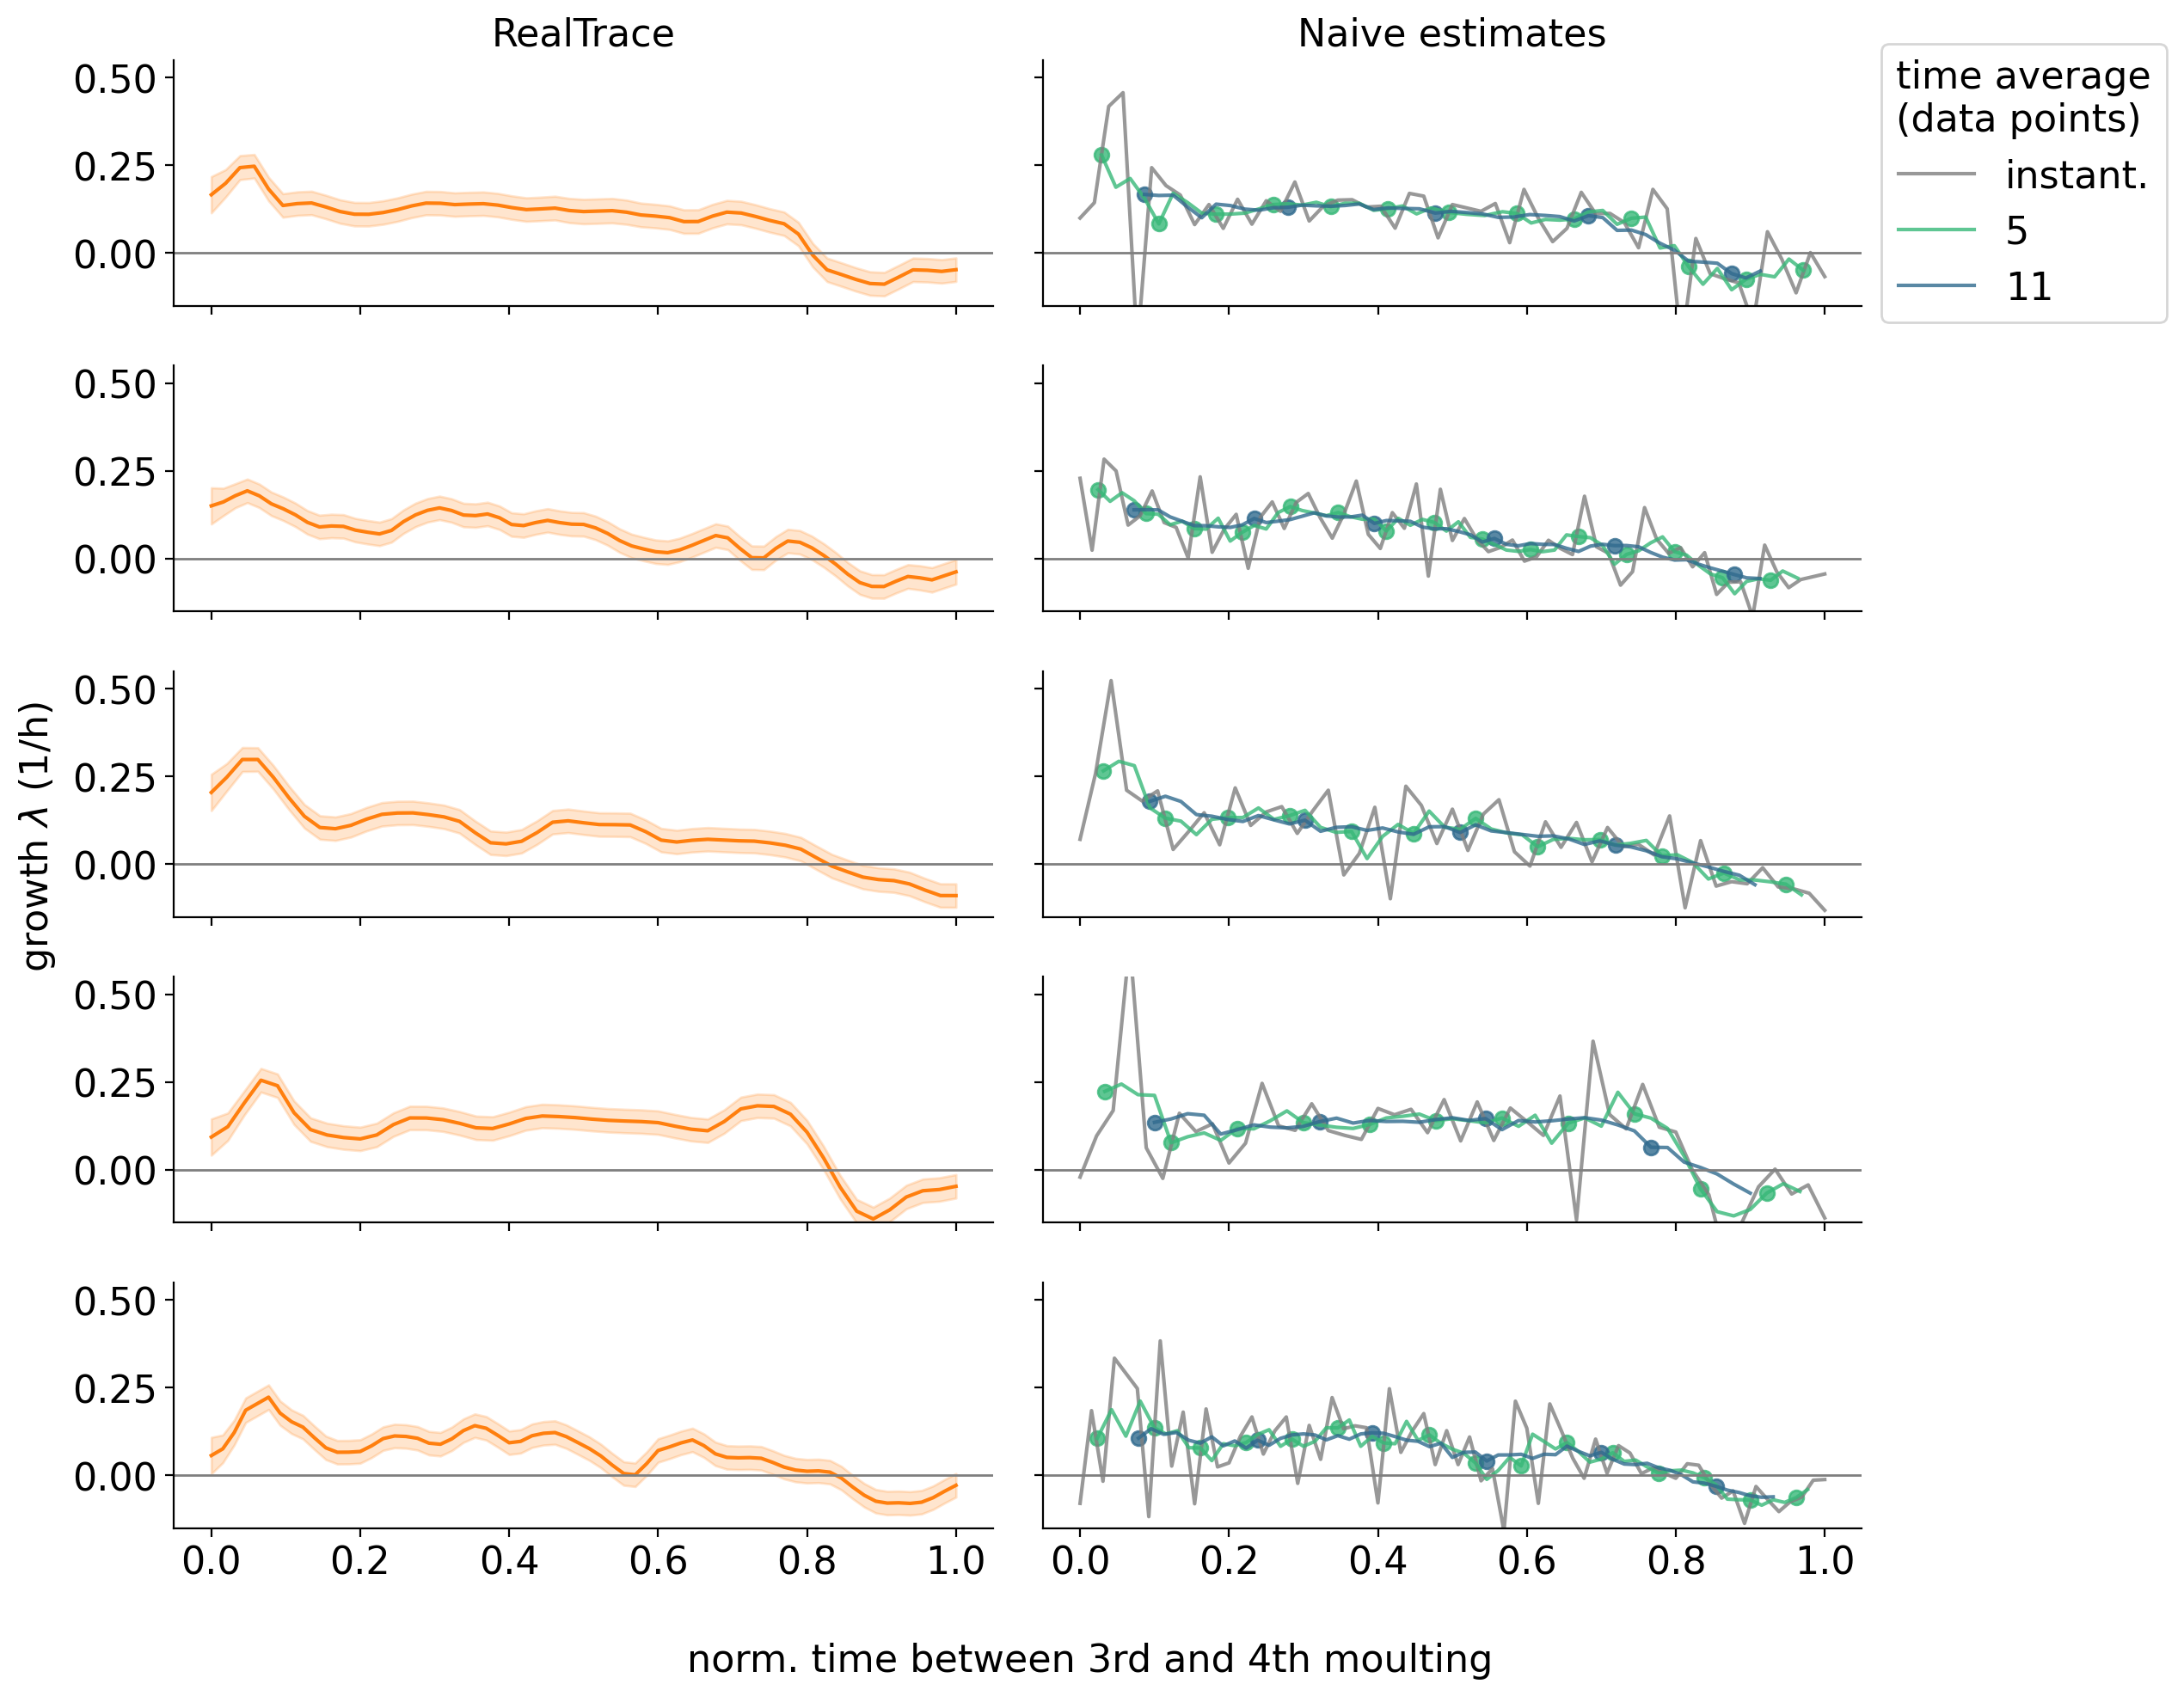

array([<AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>,
       <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>, <AxesSubplot:>,
       <AxesSubplot:>, <AxesSubplot:>], dtype=object)

In [24]:
def compare_sc_pred_vs_naive(all_cells, n_cells, outfile=None):
                         
    fig, axes = plt.subplots(n_cells,2, figsize=(FULL_SIZE,FULL_HEIGHT*n_cells*0.5), sharey=True, sharex=True)
    ax = axes.ravel()
    cells = copy.deepcopy(all_cells)
        
    np.random.seed(1)
    cells_idx = np.random.choice(np.arange(len(cells)), n_cells, replace=False)
    
    for i, idx in enumerate(cells_idx):
        t1, frame = moult_time(cells[idx], [5, 12], True)    
            
        time = (cells[idx].time - cells[idx].time[0])[:frame]
        time = time/time[-1]
        ax[2*i].plot(time, cells[idx].mean_l[:frame]*60, color="tab:orange")
        ax[2*i].fill_between(time, 
                             (cells[idx].mean_l-np.sqrt(cells[idx].cov_ll))[:frame]*60, 
                             (cells[idx].mean_l+np.sqrt(cells[idx].cov_ll))[:frame]*60, 
                             color="tab:orange", alpha=0.2)
        
    for jj, n_window in enumerate([1,4,10]):
        cmap =  matplotlib.pyplot.get_cmap("viridis_r")
        color1= cmap((jj)*0.33)
        
        if jj==0:
            color1="tab:grey"
        
        
        # cmap =  matplotlib.pyplot.get_cmap("Blues")
        
        # color1= cmap((jj)*0.33 +0.33)
        # if jj==0:
        #     color1="tab:grey"
        
        for i, idx in enumerate(cells_idx):
            t1, frame = moult_time(cells[idx], [5, 12], True)
            
            cells[idx].naive_l = np.diff(cells[idx].log_length)/np.diff(cells[idx].time)
            time = cells[idx].time[:frame]
            cells[idx].naive_l = cells[idx].naive_l[:frame]
        
            
            time = time/time[-1]
            
            time_avg = sliding_mean(time, n_window)
            rate_avg = sliding_mean(cells[idx].naive_l,  n_window)
    
    
            if n_window==1:
                label="instant."
            else:
                label =  label="{:d}".format(n_window+1)

            h = ax[2*i+1].plot(time_avg, rate_avg*60, color=color1,  alpha=0.8, label=label )
            if n_window>1:
                ax[2*i+1].scatter(time_avg[::n_window], rate_avg[::n_window]*60, color=color1,  alpha=0.8)
        
#     time=[]
#     cells = copy.deepcopy(all_cells)
    
#     for i, cell in enumerate(cells):
#         t1, frame = moult_time(cell, [5, 12], True)

#         cells[i].time = cell.time[:frame]
        
#         cells[i].mean_l = cell.mean_l[:frame]
#         cells[i].cov_ll = cell.cov_ll[:frame]
        
#         cell_time = cells[i].time/cells[i].time[-1]
        
#         time.append(cell_time)
    
#     _, yaxis = get_from_all_cells(cells, "l")
    
#     time = np.concatenate(time)

#     dt_bin = 0.02
#     bins_time = np.arange(0, 1+dt_bin, dt_bin)
#     bin_value, bin_edges, binnumber = stats.binned_statistic(time,yaxis, statistic='mean', bins=bins_time)
#     bin_std, _, _= stats.binned_statistic(time,yaxis, statistic='std', bins=bins_time)

#     ax[0].plot(bin_edges[:-1] + np.diff(bin_edges)/2., 
#                 bin_value, 
#                 alpha=1, 
#                 color="black",
#                 label="average growth")
        
        
    ax[0].set_title("RealTrace")
    ax[1].set_title("Naive estimates")
    ax[1].legend(*legend_without_duplicate_labels(ax[1]), bbox_to_anchor=(1,0.5), loc="center left", title="time average\n(data points)", ncol=1)
    
    # ax[0].xaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=3))
    # ax[0].yaxis.set_major_locator(matplotlib.ticker.MultipleLocator(base=2))
    # ax[0].yaxis.set_minor_locator(matplotlib.ticker.MultipleLocator(base=1))
        
#     ax[-2].set_xlabel("norm. time between 3rd and 4th moulting")
#     ax[-1].set_xlabel("norm. time between 3rd and 4th moulting")
    fig.supxlabel("norm. time between 3rd and 4th moulting")

    fig.supylabel(r"growth $\lambda$ (1/h)")

    for a in list(ax) :
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)

        a.spines['right'].set_color('none')
        a.yaxis.tick_left()

        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()   
        a.set_ylim(-0.15, 0.55)
        a.axhline(0,color="tab:grey", lw=1)

    fig.tight_layout()
    
    
    if outfile != None:
        plt.show()
        fig.savefig(outfile, bbox_inches='tight')
    plt.show()
    fig.clear()
    plt.close(fig)
    return ax


compare_sc_pred_vs_naive(worm_data, 5, outfile="../../figures_for_method_paper/supp/celegans/sw_celegans_growth.pdf")




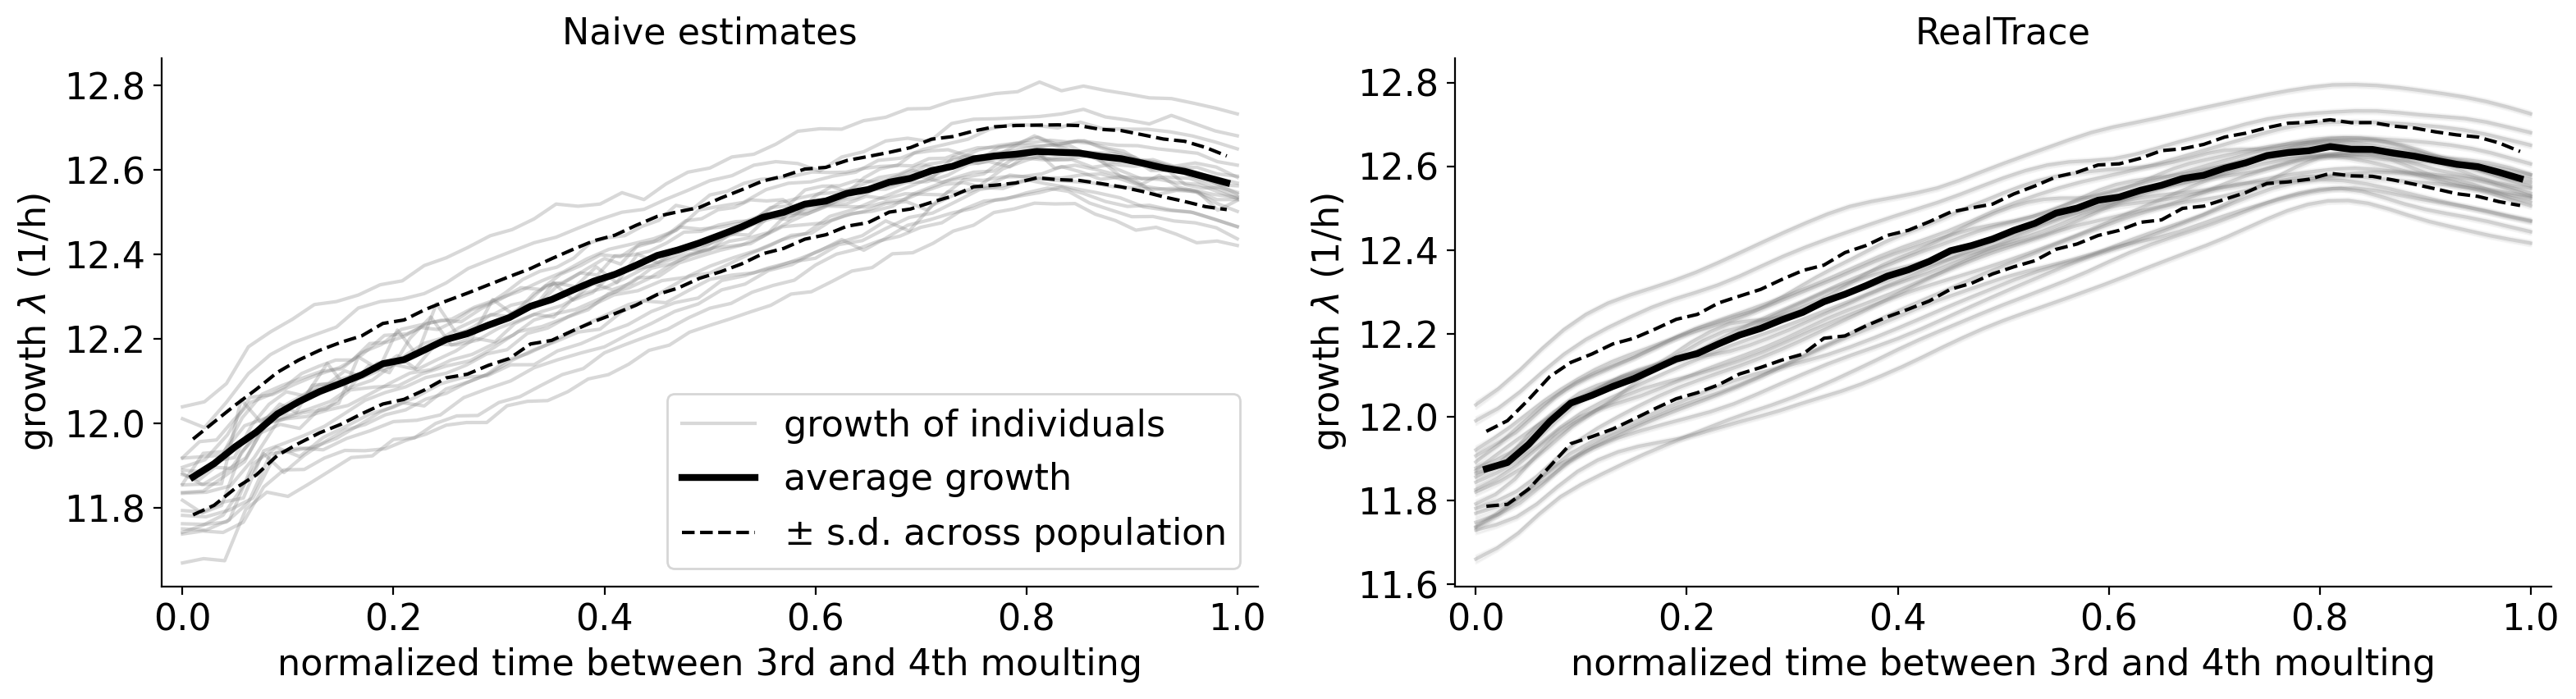

In [12]:
np.random.seed(1)

def plot_comparison_raw_realtrace_length(cells_orig, 
                           title=None, 
                           xlim = [None, None],
                           plot_file=None,
                           color="tab:blue",
                           normalize=None, 
                           ylabel=None):
    
    fig, ax = plt.subplots(1,2, figsize=(16,4.5))
    ax = ax.ravel()
    
    for a in ax:
        a.spines["top"].set_visible(False)
        a.spines["right"].set_visible(False)
        a.spines['right'].set_color('none')
        a.yaxis.tick_left()
        a.spines['top'].set_color('none')
        a.xaxis.tick_bottom()

    cells = copy.deepcopy(cells_orig)
    time = []
    idx = np.random.choice(len(cells), 20, replace=False)
    
    label = "growth of individuals"

    for i, cell in enumerate(cells):
        t1, frame = moult_time(cell, [5, 12], True)
        cells[i].naive_l = np.diff(cell.log_length)/np.diff(cell.time)
        cells[i].naive_l = cell.naive_l[:frame]
        cells[i].log_length = cell.log_length[:frame]
        
        cells[i].time = cell.time[:frame]
        
        cells[i].mean_l = cell.mean_l[:frame]
        cells[i].cov_ll = cell.cov_ll[:frame]
        
        cells[i].mean_x = cell.mean_x[:frame]
        cells[i].cov_xx = cell.cov_xx[:frame]
        
        cell_time = cells[i].time/cells[i].time[-1]
        
        time.append(cell_time)
        
        if i in idx:
            ax[0].plot(cell_time, cells[i].log_length, color="tab:grey", alpha=0.3, zorder=-1,
                      label=label)

            ax[1].plot(cell_time, cells[i].mean_x, color="tab:grey", alpha=0.3, zorder=-1,
                      label=label) 
            label=None
                        
            ax[1].fill_between(cell_time, 
                               (cells[i].mean_x-np.sqrt(cells[i].cov_xx)), 
                               (cells[i].mean_x+np.sqrt(cells[i].cov_xx)), 
                               color="tab:grey", alpha=0.07, zorder=-1)  
        
    time = np.concatenate(time)
        
    for i, rate in enumerate(["x", "log_length"]):
        _, yaxis = get_from_all_cells(cells, rate)

        dt_bin = 0.02
        bins_time = np.arange(0, 1+dt_bin, dt_bin)
        bin_value, bin_edges, binnumber = stats.binned_statistic(time,yaxis, statistic='mean', bins=bins_time)
        bin_std, _, _= stats.binned_statistic(time,yaxis, statistic='std', bins=bins_time)

        ax[i].plot(bin_edges[:-1] + np.diff(bin_edges)/2., 
                    bin_value, 
                    color=color, 
                    alpha=1, 
                    lw=3,
                    label="average growth")
        ax[i].plot(bin_edges[:-1] + np.diff(bin_edges)/2., 
                        bin_value-bin_std ,
                        color=color, 
                        alpha=1,
                        ls="--",
                        zorder=1, 
                          label= "$\pm$ s.d. across population")
        ax[i].plot(bin_edges[:-1] + np.diff(bin_edges)/2., 
                        bin_value+bin_std, 
                        color=color, 
                        alpha=1, ls="--",
                        zorder=1)
    
        

    # ax[1].legend()
    ax[0].legend()
    

    for a in ax:
        a.set_xlim(xlim)
        a.set_xlabel("normalized time between 3rd and 4th moulting")

    ax[0].set_title(r"Naive estimates")
    ax[1].set_title(r"RealTrace")
    
    ax[0].set_ylabel(r"growth $\lambda$ (1/h)")
    ax[1].set_ylabel(r"growth $\lambda$ (1/h)")

    fig.tight_layout()
    if plot_file != None: 
        fig.savefig(plot_file, dpi=600, bbox_inches='tight')
    plt.show()
    return fig, ax

 
fig, ax = plot_comparison_raw_realtrace_length(worm_data,
                                                 xlim=[-0.02, 1.02], 
                                                 color= "black",
                                                 plot_file="../../figures_for_method_paper/supp/celegans_log_length.pdf")


